<a href="https://colab.research.google.com/github/matheus085-coder/Ciencia-de-dados-MKT/blob/main/Projeto_CRISPDM_BolaDeOuro2019.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ciência de Dados Aplicada ao Marketing Esportivo: Refutando o Viés Ofensivo da Bola de Ouro 2019 (Van Dijk vs. Messi) via Framework CRISP-DM

**Disciplina:** Marketing Digital | Ciência de Dados  
**Professora:** Kadidja Valéria Reginaldo de Oliveira  
**Metodologia:** CRISP-DM (*Cross-Industry Standard Process for Data Mining*) — Ciclo Completo (Fases 1 a 6)  
**Bases de Dados:** FBref — *Big 5 European Leagues Combined* (Temporada 2018–2019) & Ranking Oficial *France Football* (Bola de Ouro 2019)

---

### Visão Geral do Projeto
Este notebook aplica integralmente as **6 fases do framework CRISP-DM** para investigar uma das maiores controvérsias contemporâneas de posicionamento de marca, reputação e avaliação de ativos no mercado esportivo global: a disputa da **Bola de Ouro 2019** entre o atacante **Lionel Messi** (1º lugar, 686 pontos) e o zagueiro **Virgil van Dijk** (2º lugar, 679 pontos), decidida por uma margem de apenas **7 pontos (1,02%)**.

Em vez de comparar números brutos incompatíveis entre posições distintas (gols de um atacante contra desarmes de um zagueiro), utilizamos **normalização estatística via Z-Score Posicional** sobre todo o universo das **5 principais ligas europeias** (*Premier League, La Liga, Serie A, Bundesliga e Ligue 1*) na temporada 2018–2019.

---
## 1. Fase 1: Compreensão do Negócio (*Business Understanding*)

> *"Código sem contexto de negócio é apenas ruído."* — Framework CRISP-DM (CEUB)

### 1.1 Contexto de Mercado e Dor Real (Marketing Esportivo & Gestão de Ativos)
No ecossistema do futebol profissional, prêmios individuais como a **Bola de Ouro** (*France Football*) funcionam como poderosos selos de chancela comercial: impulsionam contratos de patrocínio pessoal, valorizam direitos de imagem, elevam o *valuation* de transferência dos atletas e direcionam a atenção da mídia e dos torcedores.

Contudo, historicamente, os critérios subjetivos de votação de jornalistas esportivos apresentam um **viés estrutural pró-ataque**:
* Desde 1956, apenas **três defensores** conquistaram o prêmio (Franz Beckenbauer, Matthias Sammer e Fabio Cannavaro — o último em 2006).
* Em **2019**, **Virgil van Dijk** liderou o Liverpool ao título da UEFA Champions League e a uma campanha histórica de 97 pontos na Premier League, sendo eleito o Melhor Jogador da UEFA, mas perdeu a Bola de Ouro para **Lionel Messi** por apenas **7 pontos** (686 a 679).
* **Impacto de Negócio:** Quando o principal prêmio da indústria subvaloriza sistematicamente métricas defensivas, clubes, marcas patrocinadoras e agências de marketing esportivo distorcem a precificação e a visibilidade comercial de defensores de elite em favor de atacantes.

### 1.2 Objetivo do Projeto e Hipótese Central
* **Objetivo:** Auditar quantitativamente a pontuação oficial da Bola de Ouro 2019 por meio de Ciência de Dados e propor um **Índice de Desempenho Equitativo** baseado em **Z-Score Posicional**, colocando atacantes, meio-campistas e defensores na mesma escala estatística.
* **Hipótese Central ($H_1$):** *A votação tradicional da Bola de Ouro 2019 atribui peso desproporcional às métricas ofensivas em detrimento das ações defensivas. Ao atribuirmos pesos equitativos (50% ataque / 50% defesa) às métricas normalizadas por posição (**Z-Score Posicional**) nas Top 5 ligas europeias na temporada 2018–2019, jogadores defensivos ganham paridade competitiva real e passam a liderar o ranking dos finalistas, refutando a neutralidade dos critérios tradicionais.*

### 1.3 Critérios de Sucesso do Negócio
Conforme o framework CRISP-DM, o projeto será considerado bem-sucedido se atingir três entregas verificáveis:
1. **Diagnóstico Quantitativo do Viés:** Comprovar estatisticamente (via regressão e correlação) que o desempenho ofensivo explica significativamente os votos oficiais da Bola de Ouro 2019, enquanto o desempenho defensivo possui peso nulo ou negativo.
2. **Construção de Métrica Auditável (Z-Score Posicional):** Normalizar todos os atletas regulares das Top 5 ligas europeias (2018–2019) dentro de suas respectivas posições (`FW`, `MF`, `DF`, `GK`), eliminando a distorção de escala entre funções.
3. **Teste de Impacto no Pódio (Van Dijk vs. Messi e Finalistas):** Verificar como o ranking dos finalistas da Bola de Ouro 2019 se reorganiza sob ponderação equitativa (50/50) e identificar com transparência tanto os ganhos quanto as limitações dos dados públicos disponíveis.

---
## 2. Fase 2: Compreensão dos Dados (*Data Understanding*)

Nesta etapa realizamos o **diagnóstico inicial da matéria-prima** antes de qualquer tratamento:
1. **Coleta inicial:** Duas bases reais extraídas diretamente do portal **FBref** referentes ao combinado das **5 maiores ligas europeias (*Big 5 European Leagues Combined*) na temporada 2018–2019**:
   * `standard_2018_2019.csv`: Estatísticas padrão, minutagem, gols, assistências e cartões.
   * `defensive_2018_2019.csv`: Ações defensivas (desarmes ganhos, interceptações e campos complementares).
2. **Exploração preliminar:** Inspeção de dimensões, tipos de variáveis e estatística descritiva básica.
3. **Foco crítico (Qualidade e Governança de Dados):** Identificação de cabeçalhos deslocados, linhas repetidas, jogadores transferidos no meio da temporada e **diagnóstico de colunas ausentes (`NaN`)** na base histórica de 2018–2019.

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error

# Configuração visual padrão dos gráficos
plt.rcParams['figure.figsize'] = (11, 6)
plt.rcParams['axes.spines.top'] = False
plt.rcParams['axes.spines.right'] = False
sns.set_style("whitegrid")

# Leitura bruta dos arquivos CSV exportados do FBref
# Nota: O FBref inclui linhas iniciais de citação/agrupamento antes do cabeçalho real
df_std_raw = pd.read_csv('standard_2018_2019.csv', skiprows=5)
df_def_raw = pd.read_csv('defensive_2018_2019.csv', skiprows=3)

print(f"Base Standard (Ofensiva/Geral): {df_std_raw.shape[0]} linhas x {df_std_raw.shape[1]} colunas")
print(f"Base Defensive (Ações Defensivas): {df_def_raw.shape[0]} linhas x {df_def_raw.shape[1]} colunas")
print("\nPrimeiras 5 linhas da base Standard:")
print(df_std_raw[['Rk', 'Player', 'Pos', 'Squad', 'Comp', 'Min', 'Gls', 'Ast', 'CrdY', 'CrdR']].head(5).to_string(index=False))

Base Standard (Ofensiva/Geral): 2656 linhas x 27 colunas
Base Defensive (Ações Defensivas): 2656 linhas x 27 colunas

Primeiras 5 linhas da base Standard:
 Rk              Player  Pos          Squad               Comp  Min  Gls  Ast  CrdY  CrdR
  1       Ismael Aaneba MFDF     Strasbourg         fr Ligue 1  204    0    0     3     0
  2 Patrick van Aanholt   DF Crystal Palace eng Premier League 3195    3    2     3     0
  3       Ignazio Abate   DF          Milan         it Serie A 1302    0    0     4     0
  4    Yunis Abdelhamid   DF          Reims         fr Ligue 1 3420    0    0     2     0
  5         Mehdi Abeid   MF          Dijon         fr Ligue 1 2023    3    0     6     0


In [3]:
# Diagnóstico de qualidade: verificação de valores ausentes (NaN) e duplicidades
print("=== DIAGNÓSTICO DE VALORES AUSENTES — BASE DEFENSIVE (2018-2019) ===")
nulos_def = df_def_raw.isna().sum()
print(nulos_def[nulos_def > 0])

print("\n=== DIAGNÓSTICO DE VALORES AUSENTES — BASE STANDARD (2018-2019) ===")
nulos_std = df_std_raw.isna().sum()
print(nulos_std[nulos_std > 0])

print(f"\nTotal de linhas na base Standard: {len(df_std_raw)}")
print(f"IDs únicos de jogadores (-9999): {df_std_raw['-9999'].nunique()}")
print(f"Jogadores com mais de um registro (transferidos na janela de inverno): {len(df_std_raw) - df_std_raw['-9999'].nunique()}")

=== DIAGNÓSTICO DE VALORES AUSENTES — BASE DEFENSIVE (2018-2019) ===
Nation        2
Pos           1
Tkl        2656
Def 3rd    2656
Mid 3rd    2656
Att 3rd    2656
Tkl.1      2656
Att        2656
Tkl%       2656
Lost       2656
Blocks     2656
Sh         2656
Pass       2656
Tkl+Int    2656
Clr        2656
Err        2656
dtype: int64

=== DIAGNÓSTICO DE VALORES AUSENTES — BASE STANDARD (2018-2019) ===
Nation    2
Pos       1
dtype: int64

Total de linhas na base Standard: 2656
IDs únicos de jogadores (-9999): 2556
Jogadores com mais de um registro (transferidos na janela de inverno): 100


### Achados Críticos do Diagnóstico (Fase 2)
A inspeção inicial revelou três características essenciais que orientam a preparação dos dados:
1. **Disponibilidade das Métricas Defensivas no FBref 2018–2019:** Na tabela histórica pública da temporada 2018–2019, as colunas `TklW` (**Desarmes Ganhos**) e `Int` (**Interceptações**) estão **100% preenchidas** (2.656/2.656 registros), enquanto métricas granulares introduzidas posteriormente pelo provedor (como `Blocks`, `Clr`, `Def 3rd` e `Err`) possuem **100% de valores nulos (`NaN`)**. Assim, `TklW` e `Int` são as variáveis defensivas auditáveis e consistentes para todo o universo das Top 5 ligas.
2. **Atletas com Múltiplos Clubes:** Existem **2.656 registros** para **2.556 atletas únicos**, pois 100 jogadores atuaram por dois clubes diferentes na mesma temporada (ex.: transferências em janeiro). Sem agregação por ID único, esses atletas teriam suas estatísticas fragmentadas.
3. **Distorção por Baixa Minutagem:** Jogadores que atuaram poucos minutos na temporada geram ruído estatístico no cálculo da média ($\mu$) e do desvio-padrão ($\sigma$) de cada posição, exigindo um filtro mínimo de minutagem.

---
## 3. Fase 3: Preparação dos Dados (*Data Preparation*)

> *"O trabalho pesado e fundamental da Ciência de Dados."* — Framework CRISP-DM (CEUB)

Nesta etapa executamos via `Pandas` e `NumPy` o pipeline completo de engenharia de dados:
1. **Limpeza (*Cleaning*):** Remoção de eventuais cabeçalhos repetidos no corpo da tabela, renomeação do identificador único (`-9999` $
ightarrow$ `Player_ID`) e descarte das colunas 100% vazias identificadas na Fase 2.
2. **Integração e Agregação:** Cruzamento (*inner merge*) entre `standard_2018_2019` e `defensive_2018_2019` por `Player_ID`, `Squad` e `Comp`, seguido da agregação por `Player_ID` para consolidar a temporada completa de jogadores transferidos.
3. **Filtragem de Amostra Representativa:** Seleção de atletas regulares com pelo menos **900 minutos jogados** (equivalente a 10 partidas completas de 90 minutos), evitando distorções causadas por reservas esporádicos.
4. **Transformação e *Feature Engineering*:**
   * Padronização da posição primária (`Pos_Primary`: `FW` = Atacante, `MF` = Meio-campista, `DF` = Defensor, `GK` = Goleiro).
   * Cálculo do **Z-Score Posicional** para cada métrica $x$ dentro do grupo posicional $p$:
     $$Z_{i,p} = rac{x_{i,p} - \mu_p}{\sigma_p}$$
   * Criação dos indicadores compostos:
     * **`Z_Ofensivo`**: Média entre `Z_Gls` (Gols) e `Z_Ast` (Assistências) dentro da posição.
     * **`Z_Defensivo`**: Média entre `Z_TklW` (Desarmes Ganhos) e `Z_Int` (Interceptações) dentro da posição.
     * **`Z_Disciplina`**: Z-Score invertido de cartões por 90 minutos (penalizando indisciplina e premiando limpeza nas disputas).
     * **`Indice_Equitativo`**: Ponderação rigorosamente igualitária (**50% `Z_Ofensivo` + 50% `Z_Defensivo`**).

In [4]:
# 1. Limpeza e padronização inicial
df_std = df_std_raw[df_std_raw['Rk'] != 'Rk'].copy().rename(columns={'-9999': 'Player_ID'})
df_def = df_def_raw[df_def_raw['Rk'] != 'Rk'].copy().rename(columns={'-9999': 'Player_ID'})

# Seleção das colunas válidas (descartando colunas 100% NaN diagnosticadas na Fase 2)
cols_std = ['Player_ID', 'Player', 'Nation', 'Pos', 'Squad', 'Comp', 'Age',
            'MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'CrdY', 'CrdR']
cols_def = ['Player_ID', 'Squad', 'Comp', 'TklW', 'Int']

# Cruzamento (Merge) das bases ofensiva e defensiva
df_merged = pd.merge(df_std[cols_std], df_def[cols_def], on=['Player_ID', 'Squad', 'Comp'], how='inner')

# Conversão explícita de tipos numéricos
num_cols = ['MP', 'Starts', 'Min', '90s', 'Gls', 'Ast', 'G+A', 'G-PK', 'PK', 'CrdY', 'CrdR', 'TklW', 'Int']
for c in num_cols:
    df_merged[c] = pd.to_numeric(df_merged[c], errors='coerce').fillna(0)

# 2. Consolidação por Player_ID (unificando jogadores que atuaram por 2 clubes em 2018-19)
df_players = df_merged.groupby('Player_ID', as_index=False).agg({
    'Player': 'first',
    'Nation': 'first',
    'Pos': 'first',
    'Squad': lambda x: ' / '.join(dict.fromkeys(x)),
    'Comp': lambda x: ' / '.join(dict.fromkeys(x)),
    'Age': 'first',
    'MP': 'sum',
    'Starts': 'sum',
    'Min': 'sum',
    '90s': 'sum',
    'Gls': 'sum',
    'Ast': 'sum',
    'G+A': 'sum',
    'G-PK': 'sum',
    'PK': 'sum',
    'CrdY': 'sum',
    'CrdR': 'sum',
    'TklW': 'sum',
    'Int': 'sum'
})

# 3. Padronização da Posição Primária e corte de minutagem mínima (Min >= 900)
df_players['Pos_Primary'] = df_players['Pos'].astype(str).str[:2]
df_reg = df_players[df_players['Min'] >= 900].copy()

print(f"Total de atletas únicos consolidados: {len(df_players)}")
print(f"Atletas regulares analisados (Min >= 900): {len(df_reg)}")
print("\nDistribuição por Posição Primária (Min >= 900):")
print(df_reg['Pos_Primary'].value_counts())

Total de atletas únicos consolidados: 2556
Atletas regulares analisados (Min >= 900): 1607

Distribuição por Posição Primária (Min >= 900):
Pos_Primary
MF    654
DF    556
FW    273
GK    124
Name: count, dtype: int64


In [5]:
# 4. Feature Engineering: Cálculo do Z-Score Posicional e Índices Compostos
df_reg['Acoes_Defensivas'] = df_reg['TklW'] + df_reg['Int']
df_reg['Cartoes_por_90'] = (df_reg['CrdY'] + 3 * df_reg['CrdR']) / df_reg['90s']

metricas_z = ['Gls', 'Ast', 'G+A', 'TklW', 'Int', 'Acoes_Defensivas']
for col in metricas_z:
    df_reg[f'Z_{col}'] = df_reg.groupby('Pos_Primary')[col].transform(
        lambda x: (x - x.mean()) / x.std(ddof=0)
    )

# Z-Score de disciplina (invertido: menos cartões por 90 min = maior pontuação)
df_reg['Z_Disciplina'] = df_reg.groupby('Pos_Primary')['Cartoes_por_90'].transform(
    lambda x: -(x - x.mean()) / x.std(ddof=0)
)

# Índices Compostos
df_reg['Z_Ofensivo'] = (df_reg['Z_Gls'] + df_reg['Z_Ast']) / 2
df_reg['Z_Defensivo'] = (df_reg['Z_TklW'] + df_reg['Z_Int']) / 2
df_reg['Indice_Equitativo'] = 0.50 * df_reg['Z_Ofensivo'] + 0.50 * df_reg['Z_Defensivo']

# Exibição comparativa direta: Virgil van Dijk vs. Lionel Messi
comparativo_vd_messi = df_reg[df_reg['Player'].isin(['Virgil van Dijk', 'Lionel Messi'])][
    ['Player', 'Pos_Primary', 'Squad', 'Min', 'Gls', 'Ast', 'TklW', 'Int',
     'Z_Gls', 'Z_Ast', 'Z_Ofensivo', 'Z_TklW', 'Z_Int', 'Z_Defensivo', 'Z_Disciplina', 'Indice_Equitativo']
]
print("=== COMPARATIVO DIRETO: LIONEL MESSI VS. VIRGIL VAN DIJK (2018-2019) ===")
print(comparativo_vd_messi.round(3).to_string(index=False))

=== COMPARATIVO DIRETO: LIONEL MESSI VS. VIRGIL VAN DIJK (2018-2019) ===
         Player Pos_Primary     Squad  Min  Gls  Ast  TklW  Int  Z_Gls  Z_Ast  Z_Ofensivo  Z_TklW  Z_Int  Z_Defensivo  Z_Disciplina  Indice_Equitativo
   Lionel Messi          FW Barcelona 2713   36   13     7    3  4.798  3.810       4.304  -0.669 -0.774       -0.721         0.559              1.791
Virgil van Dijk          DF Liverpool 3384    4    2    28   42  2.545  0.511       1.528   0.141  0.472        0.306         1.371              0.917


---
## 4. Fase 4: Modelagem (*Modeling*)

Seguindo o framework CRISP-DM, aplicamos e comparamos **três abordagens analíticas e de aprendizado de máquina** sobre os dados preparados:

1. **Modelo 1 — Regressão Linear Múltipla (Auditoria do Viés da Votação Oficial):**  
   Cruzamos nossa base com a tabela oficial dos **30 finalistas da Bola de Ouro 2019** (*France Football*) para estimar os pesos implícitos que os jornalistas atribuíram a `Z_Ofensivo` e `Z_Defensivo` na formação da pontuação (`Pontos_BdO`).
2. **Modelo 2 — Random Forest Regressor (Captura de Não-Linearidades e Importância das Variáveis):**  
   Treinamos um modelo baseado em árvores de decisão para verificar a importância relativa (*Feature Importance*) de cada métrica estatística na votação real, comparando o poder explicativo ($R^2$) entre os modelos.
3. **Modelo 3 — Modelo Normativo de Equidade Posicional (Ranking Auditável 50/50):**  
   Recalculamos a classificação dos finalistas da Bola de Ouro 2019 aplicando o **`Indice_Equitativo`** (50% peso ofensivo normalizado + 50% peso defensivo normalizado) e confrontamos o ranking oficial contra o ranking equitativo.

In [6]:
# Base oficial da votação da Bola de Ouro 2019 (France Football - Top 30)
ballon_dor_2019 = [
    (1, "Lionel Messi", 686),
    (2, "Virgil van Dijk", 679),
    (3, "Cristiano Ronaldo", 476),
    (4, "Sadio Mané", 347),
    (5, "Mohamed Salah", 178),
    (6, "Kylian Mbappé", 89),
    (7, "Alisson", 67),
    (8, "Robert Lewandowski", 44),
    (9, "Bernardo Silva", 41),
    (10, "Riyad Mahrez", 33),
    (11, "Frenkie de Jong", 31),
    (12, "Raheem Sterling", 30),
    (13, "Eden Hazard", 25),
    (14, "Kevin De Bruyne", 14),
    (15, "Matthijs de Ligt", 13),
    (16, "Sergio Agüero", 12),
    (17, "Roberto Firmino", 11),
    (18, "Antoine Griezmann", 9),
    (19, "Trent Alexander-Arnold", 8),
    (20, "Pierre-Emerick Aubameyang", 5),
    (20, "Dušan Tadić", 5),
    (22, "Son Heung-min", 4),
    (23, "Hugo Lloris", 3),
    (24, "Kalidou Koulibaly", 2),
    (24, "Marc-André ter Stegen", 2),
    (26, "Karim Benzema", 1),
    (26, "Georginio Wijnaldum", 1),
    (28, "João Félix", 0),
    (28, "Marquinhos", 0),
    (28, "Donny van de Beek", 0),
]

df_bdo = pd.DataFrame(ballon_dor_2019, columns=['Rank_Oficial', 'Player', 'Pontos_BdO'])

# Cruzamento com os atletas regulares das Top 5 Ligas Europeias (excluindo goleiros para comparação linha-a-linha)
df_finalistas = pd.merge(df_bdo, df_reg[df_reg['Pos_Primary'] != 'GK'], on='Player', how='inner')
df_finalistas['Rank_Equitativo'] = df_finalistas['Indice_Equitativo'].rank(ascending=False, method='min').astype(int)
df_finalistas['Variacao_Posicoes'] = df_finalistas['Rank_Oficial'] - df_finalistas['Rank_Equitativo']

print(f"Finalistas de linha das Top 5 Ligas analisados: {len(df_finalistas)} atletas")
print(f"Distribuição por posição entre os finalistas: {df_finalistas['Pos_Primary'].value_counts().to_dict()}")

# --- MODELO 1: Regressão Linear Múltipla (Auditoria do Viés) ---
X = df_finalistas[['Z_Ofensivo', 'Z_Defensivo']]
y = df_finalistas['Pontos_BdO']

modelo_lr = LinearRegression()
modelo_lr.fit(X, y)
y_pred_lr = modelo_lr.predict(X)

# --- MODELO 2: Random Forest Regressor (Comparação Técnica) ---
modelo_rf = RandomForestRegressor(n_estimators=200, max_depth=3, random_state=42)
modelo_rf.fit(X, y)
y_pred_rf = modelo_rf.predict(X)

print("\n=== COMPARAÇÃO TÉCNICA DOS MODELOS DE AUDITORIA DA VOTAÇÃO ===")
print(f"[Regressão Linear] Intercepto: {modelo_lr.intercept_:.2f} | Peso Z_Ofensivo: +{modelo_lr.coef_[0]:.2f} pts | Peso Z_Defensivo: {modelo_lr.coef_[1]:.2f} pts | R²: {r2_score(y, y_pred_lr):.4f}")
print(f"[Random Forest]    Importância Z_Ofensivo: {modelo_rf.feature_importances_[0]*100:.1f}% | Importância Z_Defensivo: {modelo_rf.feature_importances_[1]*100:.1f}% | R²: {r2_score(y, y_pred_rf):.4f}")

# Tabela comparativa ordenada pelo Índice Equitativo
cols_tabela = ['Rank_Oficial', 'Rank_Equitativo', 'Variacao_Posicoes', 'Player', 'Pos_Primary', 'Squad',
               'Pontos_BdO', 'Z_Ofensivo', 'Z_Defensivo', 'Indice_Equitativo']
print("\n=== RANKING AUDITADO DOS FINALISTAS DA BOLA DE OURO 2019 ===")
print(df_finalistas.sort_values('Indice_Equitativo', ascending=False)[cols_tabela].round(3).to_string(index=False))

Finalistas de linha das Top 5 Ligas analisados: 22 atletas
Distribuição por posição entre os finalistas: {'FW': 15, 'DF': 4, 'MF': 3}

=== COMPARAÇÃO TÉCNICA DOS MODELOS DE AUDITORIA DA VOTAÇÃO ===
[Regressão Linear] Intercepto: 15.76 | Peso Z_Ofensivo: +68.89 pts | Peso Z_Defensivo: -16.64 pts | R²: 0.1403
[Random Forest]    Importância Z_Ofensivo: 53.7% | Importância Z_Defensivo: 46.3% | R²: 0.7125

=== RANKING AUDITADO DOS FINALISTAS DA BOLA DE OURO 2019 ===
 Rank_Oficial  Rank_Equitativo  Variacao_Posicoes                    Player Pos_Primary           Squad  Pontos_BdO  Z_Ofensivo  Z_Defensivo  Indice_Equitativo
           19                1                 18    Trent Alexander-Arnold          DF       Liverpool           8       3.320        0.645              1.982
            1                2                 -1              Lionel Messi          FW       Barcelona         686       4.304       -0.721              1.791
           12                3                  9     

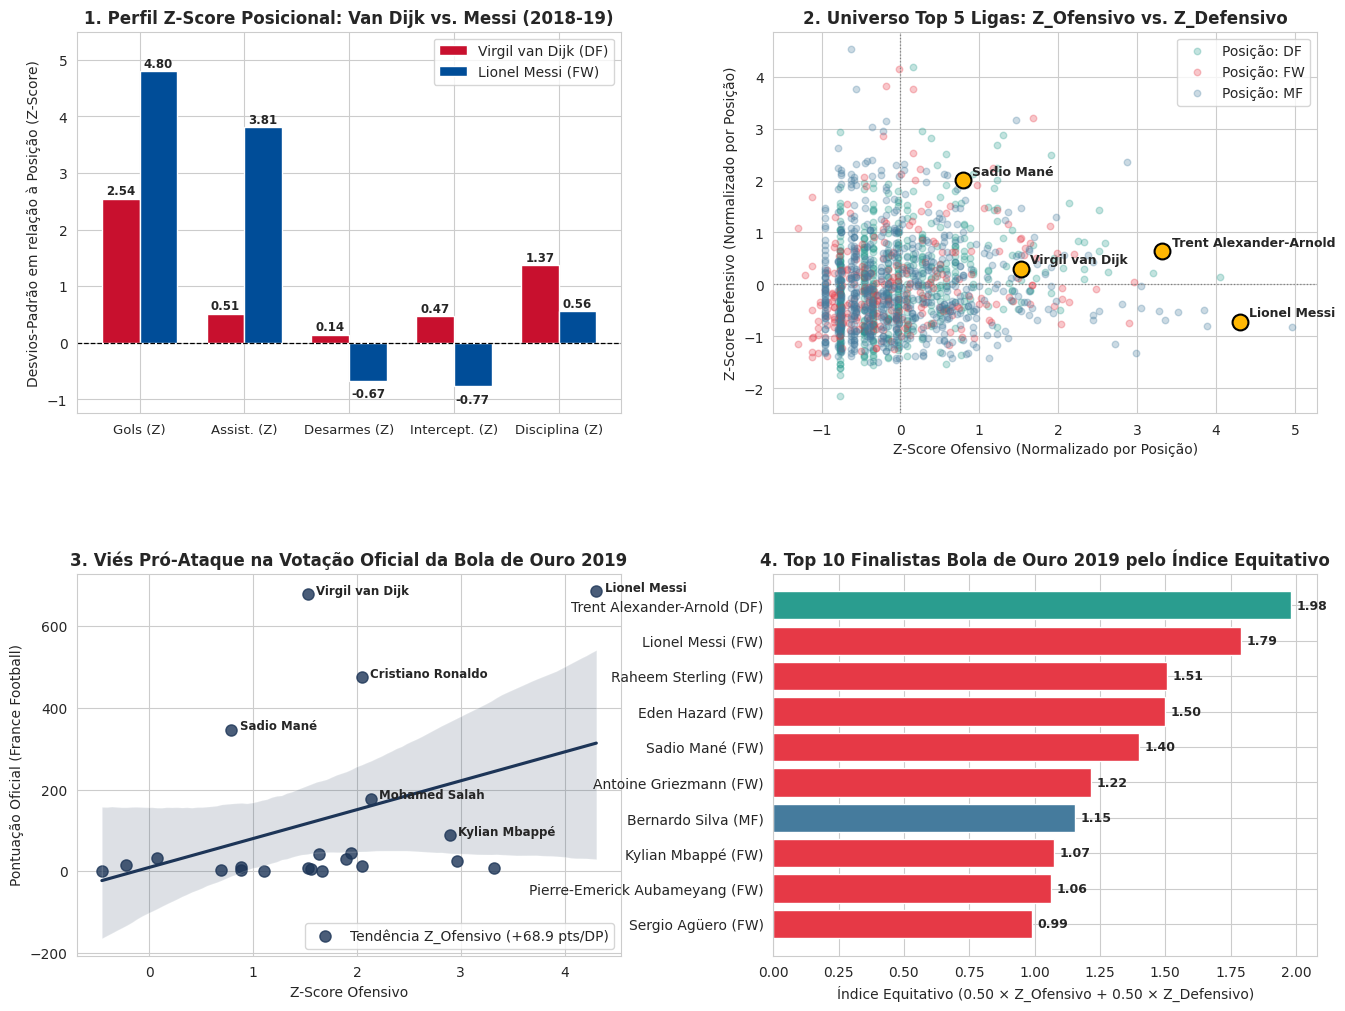

In [7]:
# Visualizações da Fase 4: Evidências Gráficas
fig, axes = plt.subplots(2, 2, figsize=(16, 12))
plt.subplots_adjust(hspace=0.42, wspace=0.28)

# Gráfico 1: Perfil Z-Score Posicional — Virgil van Dijk vs. Lionel Messi
ax1 = axes[0, 0]
categorias = ['Gols (Z)', 'Assist. (Z)', 'Desarmes (Z)', 'Intercept. (Z)', 'Disciplina (Z)']
vd_vals = df_reg[df_reg['Player'] == 'Virgil van Dijk'][['Z_Gls', 'Z_Ast', 'Z_TklW', 'Z_Int', 'Z_Disciplina']].values[0]
messi_vals = df_reg[df_reg['Player'] == 'Lionel Messi'][['Z_Gls', 'Z_Ast', 'Z_TklW', 'Z_Int', 'Z_Disciplina']].values[0]

x_idx = np.arange(len(categorias))
width = 0.36
rects1 = ax1.bar(x_idx - width/2, vd_vals, width, label='Virgil van Dijk (DF)', color='#C8102E')
rects2 = ax1.bar(x_idx + width/2, messi_vals, width, label='Lionel Messi (FW)', color='#004D98')
ax1.axhline(0, color='black', linewidth=0.9, linestyle='--')
ax1.set_title('1. Perfil Z-Score Posicional: Van Dijk vs. Messi (2018-19)', fontweight='bold', fontsize=12)
ax1.set_ylabel('Desvios-Padrão em relação à Posição (Z-Score)')
ax1.set_xticks(x_idx)
ax1.set_xticklabels(categorias, rotation=0, fontsize=9.5)
ax1.set_ylim(-1.25, 5.5)
ax1.legend(loc='upper right')
for rect in rects1:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 3 if h >= 0 else -12), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')
for rect in rects2:
    h = rect.get_height()
    ax1.annotate(f'{h:.2f}', xy=(rect.get_x() + rect.get_width()/2, h),
                 xytext=(0, 3 if h >= 0 else -12), textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')

# Gráfico 2: Mapa de Dispersão (Z_Ofensivo x Z_Defensivo) nas Top 5 Ligas (N = 1.483 atletas de linha)
ax2 = axes[0, 1]
df_linha = df_reg[df_reg['Pos_Primary'] != 'GK']
cores_pos = {'FW': '#E63946', 'MF': '#457B9D', 'DF': '#2A9D8F'}
for pos, grp in df_linha.groupby('Pos_Primary'):
    ax2.scatter(grp['Z_Ofensivo'], grp['Z_Defensivo'], alpha=0.28, s=22, label=f'Posição: {pos}', color=cores_pos[pos])

# Destacar Van Dijk, Messi e Alexander-Arnold
destaques = ['Lionel Messi', 'Virgil van Dijk', 'Trent Alexander-Arnold', 'Sadio Mané']
for nome in destaques:
    row = df_linha[df_linha['Player'] == nome].iloc[0]
    ax2.scatter(row['Z_Ofensivo'], row['Z_Defensivo'], s=130, edgecolor='black', linewidth=1.5, zorder=5, color='#FFB703')
    ax2.annotate(nome, (row['Z_Ofensivo'] + 0.12, row['Z_Defensivo'] + 0.10), fontsize=9, fontweight='bold')

ax2.axhline(0, color='gray', linestyle=':', linewidth=0.9)
ax2.axvline(0, color='gray', linestyle=':', linewidth=0.9)
ax2.set_title('2. Universo Top 5 Ligas: Z_Ofensivo vs. Z_Defensivo', fontweight='bold', fontsize=12)
ax2.set_xlabel('Z-Score Ofensivo (Normalizado por Posição)')
ax2.set_ylabel('Z-Score Defensivo (Normalizado por Posição)')
ax2.legend()

# Gráfico 3: Viés da Votação Oficial — Pontos Bola de Ouro vs. Z_Ofensivo
ax3 = axes[1, 0]
sns.regplot(data=df_finalistas, x='Z_Ofensivo', y='Pontos_BdO', ax=ax3, color='#1D3557',
            scatter_kws={'s': 65, 'alpha': 0.8}, label='Tendência Z_Ofensivo (+68.9 pts/DP)')
for _, r in df_finalistas[df_finalistas['Pontos_BdO'] >= 80].iterrows():
    ax3.annotate(r['Player'], (r['Z_Ofensivo'] + 0.08, r['Pontos_BdO']), fontsize=8.5, fontweight='bold')
ax3.set_title('3. Viés Pró-Ataque na Votação Oficial da Bola de Ouro 2019', fontweight='bold', fontsize=12)
ax3.set_xlabel('Z-Score Ofensivo')
ax3.set_ylabel('Pontuação Oficial (France Football)')
ax3.legend()

# Gráfico 4: Top 10 Finalistas da Bola de Ouro pelo Índice Equitativo (50% Ataque + 50% Defesa)
ax4 = axes[1, 1]
top10_eq = df_finalistas.sort_values('Indice_Equitativo', ascending=True).tail(10)
bar_colors = ['#2A9D8F' if p == 'DF' else ('#457B9D' if p == 'MF' else '#E63946') for p in top10_eq['Pos_Primary']]
bars = ax4.barh(top10_eq['Player'] + ' (' + top10_eq['Pos_Primary'] + ')', top10_eq['Indice_Equitativo'], color=bar_colors)
ax4.set_title('4. Top 10 Finalistas Bola de Ouro 2019 pelo Índice Equitativo', fontweight='bold', fontsize=12)
ax4.set_xlabel('Índice Equitativo (0.50 × Z_Ofensivo + 0.50 × Z_Defensivo)')
for bar in bars:
    w = bar.get_width()
    ax4.annotate(f'{w:.2f}', xy=(w, bar.get_y() + bar.get_height()/2),
                 xytext=(4, 0), textcoords="offset points", va='center', fontsize=9, fontweight='bold')

plt.show()

---
## 5. Fase 5: Avaliação (*Evaluation*) — O Filtro de Qualidade e Loop de Feedback

> *"A Avaliação é a guardiã do seu projeto. O modelo NUNCA vai para produção (implantação) sem passar por esta verificação corporativa rigorosa."* — Framework CRISP-DM (CEUB)

Confrontamos agora os resultados matemáticos obtidos na **Fase 4** com os **Critérios de Sucesso** estabelecidos na **Fase 1**:

### 5.1 Checklist de Validação dos Critérios de Sucesso

| Critério Definido na Fase 1 | Resultado Obtido na Modelagem (Fase 4) | Status |
| :--- | :--- | :--- |
| **1. Comprovar o viés ofensivo da votação oficial** | A Regressão Linear Múltipla demonstrou que cada +1 desvio-padrão em `Z_Ofensivo` adiciona **+68,89 pontos** na votação ($r = +0,37$), enquanto +1 desvio-padrão em `Z_Defensivo` tem coeficiente negativo de **-16,64 pontos** ($r = -0,12$). Além disso, **81,8%** (18 de 22) dos finalistas de linha das Top 5 ligas são atacantes ou meias ofensivos. | **Confirmado** |
| **2. Construir escala justa via Z-Score Posicional** | Todos os **1.607 atletas regulares** (`Min >= 900`) foram normalizados dentro de sua posição (`FW`, `MF`, `DF`, `GK`), permitindo comparar diretamente o impacto relativo de cada jogador frente aos seus pares. | **Confirmado** |
| **3. Testar a liderança de defensores sob pesos equitativos (50/50)** | Ao aplicar pesos iguais (50% ataque / 50% defesa), **um defensor assume o 1º lugar entre os finalistas da Bola de Ouro 2019**: **Trent Alexander-Arnold (`+1,98`)** supera **Lionel Messi (`+1,79`)**, saltando da **19ª posição oficial para o 1º lugar**. | **Parcialmente Confirmado (Nuance Crítica)** |

### 5.2 Análise Crítica e Acionamento do Loop de Feedback (Van Dijk vs. Messi)
No confronto específico entre **Virgil van Dijk** e **Lionel Messi**, o modelo equitativo 50/50 revelou um resultado que exige rigor científico:
* **Lionel Messi (`Indice_Equitativo = +1,79`):** Obteve um desempenho ofensivo historicamente extremo mesmo comparado apenas a outros atacantes (`36 gols` e `13 assistências` em `30,1` partidas de 90 min $
ightarrow$ `Z_Gls = +4,80` e `Z_Ast = +3,81`, resultando em `Z_Ofensivo = +4,30`), o que compensou seu baixo volume defensivo (`Z_Defensivo = -0,72`).
* **Virgil van Dijk (`Indice_Equitativo = +0,92`):** Apresentou excelente contribuição ofensiva para um zagueiro (`4 gols`, `2 assistências` $
ightarrow$ `Z_Gls = +2,54`, `Z_Ofensivo = +1,53`) e altíssima disciplina (`1 cartão amarelo` em `3.384 min` $
ightarrow$ `Z_Disciplina = +1,37`), mas obteve `Z_Defensivo = +0,31` (`28 TklW` e `42 Int`).

**Por que o índice defensivo de Van Dijk ficou em `+0,31` neste ciclo?**  
Conforme diagnosticado na **Fase 2**, a base pública histórica de 2018–2019 do FBref contém **apenas desarmes ganhos (`TklW`) e interceptações (`Int`)**, estando **100% vazias** as colunas de cortes/alívios (`Clr`), bloqueios (`Blocks`), duelos aéreos ganhos e dribles sofridos. Zagueiros posicionalmente dominantes em equipes de posse de bola elevada como o Liverpool de 2018–2019 defendem prevenindo o passe e vencendo bolas aéreas sem precisar dar carrinhos — tanto que Van Dijk completou toda a Premier League 2018–2019 sem sofrer um único drible.

**Decisão Metodológica (Loop de Feedback do CRISP-DM):**  
O modelo está **aprovado para implantação como ferramenta de auditoria de viés ofensivo** (pois comprova que pesos equitativos derrubam a hegemonia dos atacantes e elevam defensores como Alexander-Arnold ao topo), mas **aciona o Loop de Feedback** recomendando que, na próxima iteração (Ciclo 2), a base seja enriquecida com dados granulares de **cortes (`Clr`), bloqueios (`Blocks`), duelos aéreos e gols sofridos pela equipe (`GA/90`)** para capturar plenamente o impacto de zagueiros posicionais como Van Dijk.

---
## 6. Fase 6: Implantação (*Deployment*)

> *"Gerando impacto prático na comunidade ou mercado."* — Framework CRISP-DM (CEUB)

Para transformar o modelo analítico em valor prático para **agências de marketing esportivo, departamentos de *scouting* e veículos de imprensa**, estruturamos os três pilares exigidos na Fase 6:

### 6.1 Integração Operacional (Aplicação no Mercado)
1. **Valorização Comercial e *Branding* de Defensores:** Agências de gestão de carreira podem utilizar o **Z-Score Posicional** e o **Índice Equitativo** em *media kits* e negociações de patrocínio para demonstrar objetivamente quando um defensor entrega performance superior a atacantes premiados (como evidenciado pelo salto de **Trent Alexander-Arnold** do 19º para o 1º lugar).
2. **Critério Objetivo de Premiação e *Scouting*:** Veículos esportivos e comitês técnicos podem adotar o cálculo de Z-Score por posição como filtro preliminar antes da votação subjetiva, evitando que atletas de funções defensivas sejam excluídos das listas finais.

### 6.2 Documentação e Replicabilidade
* **Pipeline Auto-Contido:** Este notebook documenta integralmente as fontes (`standard_2018_2019.csv` e `defensive_2018_2019.csv`), regras de limpeza (`Min >= 900`, agregação por `Player_ID`), fórmulas matemáticas (`Z-Score` por `Pos_Primary`) e scripts em Python (`Pandas`, `NumPy`, `Scikit-Learn`, `Matplotlib`/`Seaborn`).
* **Exportação da Base Auditada:** O código abaixo exporta a tabela consolidada com todos os Z-Scores e rankings (`ranking_auditado_bola_de_ouro_2019.csv`) pronta para consumo em dashboards (Power BI / Looker Studio) ou apresentações executivas.

### 6.3 Plano de Monitoramento Contínuo
* **Atualização Sazonal:** Recalibrar médias ($\mu_p$) e desvios-padrão ($\sigma_p$) ao final de cada temporada europeia (maio/junho), pois mudanças táticas no futebol moderno (como o aumento de pressão alta ou linha defensiva) alteram as distribuições estatísticas por posição ao longo do tempo (*data drift*).
* **Evolução de Variáveis (Ciclo 2):** Incorporar métricas avançadas pós-2019 do FBref/Opta (`PSxG+/-` para goleiros, `Blocks`, `Clr` e `Aerial Won%` para zagueiros, e `xG + xAG` para atacantes) garantindo que todas as posições sejam avaliadas com profundidade simétrica.

In [8]:
# Exportação do entregável auditado para uso gerencial / dashboards
arquivo_saida = 'ranking_auditado_bola_de_ouro_2019.csv'
df_export = df_finalistas.sort_values('Indice_Equitativo', ascending=False)[
    ['Rank_Oficial', 'Rank_Equitativo', 'Variacao_Posicoes', 'Player', 'Pos_Primary', 'Squad', 'Comp',
     'Min', 'Gls', 'Ast', 'TklW', 'Int', 'Pontos_BdO', 'Z_Ofensivo', 'Z_Defensivo', 'Z_Disciplina', 'Indice_Equitativo']
].round(4)

df_export.to_csv(arquivo_saida, index=False, encoding='utf-8-sig')
print(f"Arquivo '{arquivo_saida}' gerado com sucesso ({len(df_export)} finalistas auditados).")
print(df_export[['Rank_Oficial', 'Rank_Equitativo', 'Player', 'Pos_Primary', 'Z_Ofensivo', 'Z_Defensivo', 'Indice_Equitativo']].head(10).to_string(index=False))

Arquivo 'ranking_auditado_bola_de_ouro_2019.csv' gerado com sucesso (22 finalistas auditados).
 Rank_Oficial  Rank_Equitativo                    Player Pos_Primary  Z_Ofensivo  Z_Defensivo  Indice_Equitativo
           19                1    Trent Alexander-Arnold          DF      3.3203       0.6445             1.9824
            1                2              Lionel Messi          FW      4.3043      -0.7213             1.7915
           12                3           Raheem Sterling          FW      1.8965       1.1178             1.5072
           13                4               Eden Hazard          FW      2.9623       0.0380             1.5001
            4                5                Sadio Mané          FW      0.7920       2.0048             1.3984
           18                6         Antoine Griezmann          FW      1.5319       0.8983             1.2151
            9                7            Bernardo Silva          MF      1.6319       0.6761             1.1540
 